Chia dữ liệu ra thành train-test với tỉ lệ 90-10

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from scipy.stats import ks_2samp

In [2]:
import pandas as pd
from pathlib import Path

# Đọc parquet (nhanh hơn CSV ~5-10x) — output của notebook 02_1
train_df = pd.read_parquet("../data/clean/clean_data_train.parquet")
test_df  = pd.read_parquet("../data/clean/clean_data_test.parquet")

# Gộp lại làm df chung cho các cell EDA tiếp theo
df = pd.concat([train_df, test_df], ignore_index=True)

print(f"Train set: {train_df.shape}")
print(f"Test set:  {test_df.shape}")
print(f"Combined : {df.shape}")

Train set: (453679, 21)
Test set:  (56818, 21)
Combined : (510497, 21)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 510497 entries, 0 to 510496
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 510497 non-null  int64  
 1   job_title          510497 non-null  str    
 2   company_name       510497 non-null  str    
 3   salary             510497 non-null  str    
 4   location           510497 non-null  str    
 5   job_type           510497 non-null  str    
 6   job_industry       510497 non-null  str    
 7   experience_level   510497 non-null  str    
 8   education_level    510497 non-null  str    
 9   job_position       510497 non-null  str    
 10  job_description    510497 non-null  str    
 11  benefits           510497 non-null  str    
 12  requirements       510497 non-null  str    
 13  year               510497 non-null  int64  
 14  salary_min         500205 non-null  float64
 15  salary_max         500205 non-null  float64
 16  parse_status 

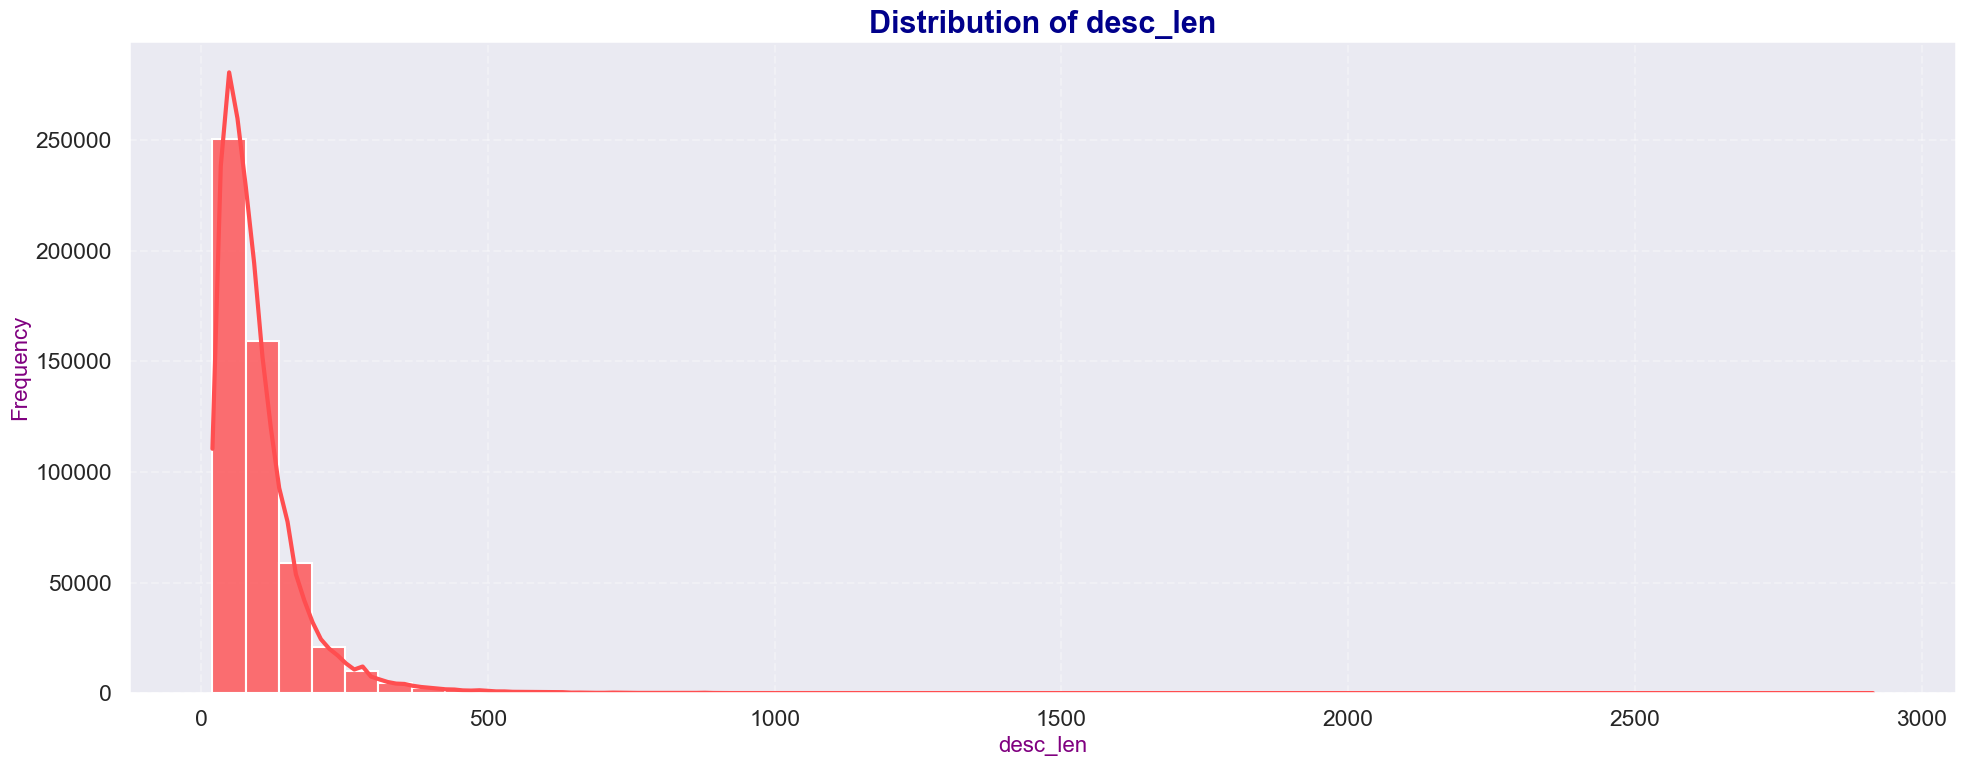

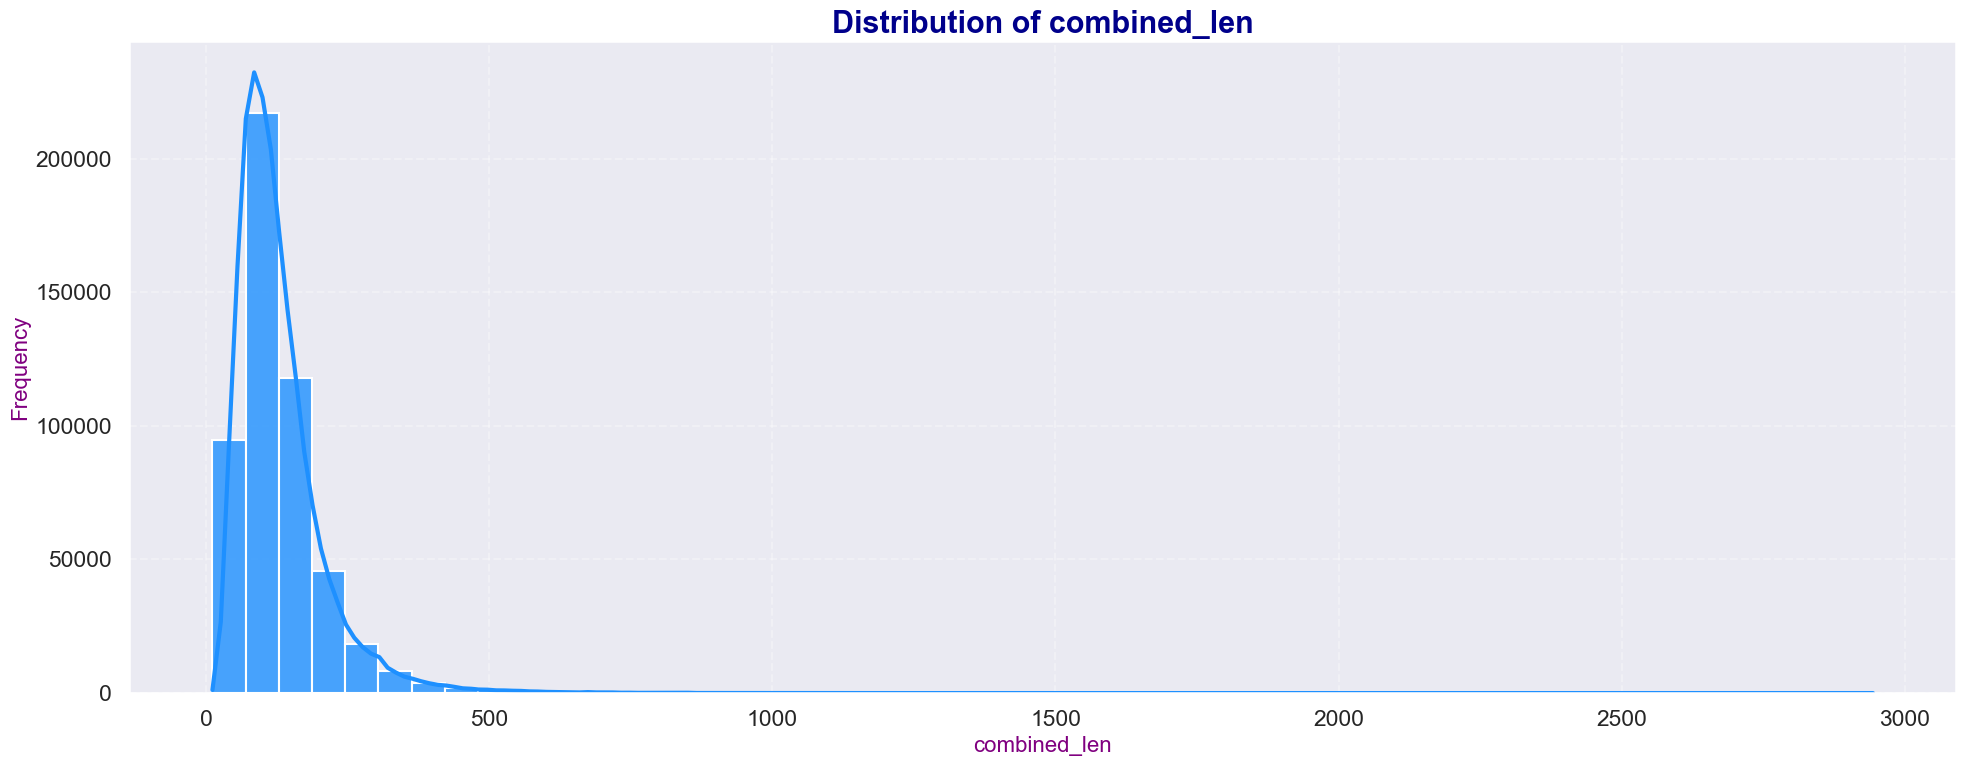

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# style tổng thể
sns.set_style("darkgrid")
sns.set_context("talk")

numerical_cols = [
    'salary_min',
    'salary_max',
    'desc_len',
    'combined_len',
]

summary_stats = df[numerical_cols].describe().T
summary_stats

# màu nổi bật cho từng cột
colors = {
    'desc_len': '#FF4E50',       # đỏ cam
    'combined_len': '#1E90FF',  # xanh dương
}

for col in numerical_cols:
    if col not in ['salary_min', 'salary_max']:
        plt.figure(figsize=(20, 8))

        sns.histplot(
            df[col],
            bins=50,
            kde=True,
            color=colors.get(col, '#8A2BE2'),
            edgecolor='white',
            alpha=0.8,
            line_kws={'linewidth': 3, 'color': 'yellow'}  # KDE nổi bật
        )

        plt.title(
            f'Distribution of {col}',
            fontsize=22,
            fontweight='bold',
            color='darkblue'
        )
        plt.xlabel(col, fontsize=16, color='purple')
        plt.ylabel("Frequency", fontsize=16, color='purple')

        plt.grid(alpha=0.3, linestyle='--')
        plt.tight_layout()
        plt.show()

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# style tổng thể
sns.set_style("whitegrid")
sns.set_context("talk")

# palette tươi sáng
palette = sns.color_palette("Set2", 10)
pie_colors = sns.color_palette("pastel")

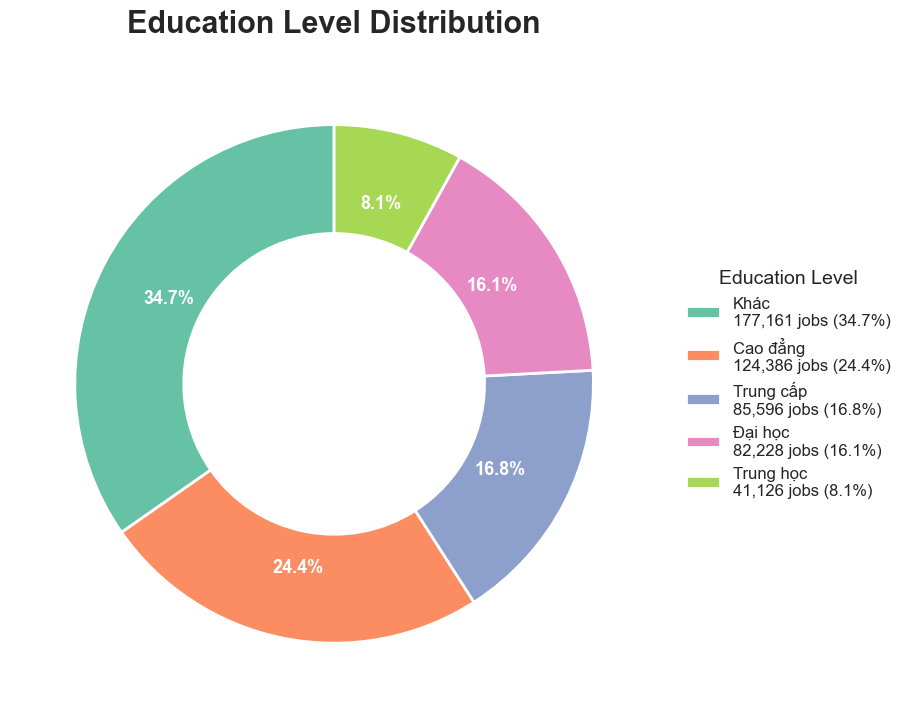

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# =========================
# MODERN SEABORN STYLE
# =========================
sns.set_theme(
    style="white",
    context="talk"
)

# =========================
# CLEAN EDUCATION LEVEL
# =========================
edu = (
    df['education_level']
    .fillna('')
    .str.lower()
    .str.strip()
)

# =========================
# GROUP EDUCATION
# =========================
edu_grouped = pd.Series(
    edu.apply(lambda x:
        'Đại học' if ('đại học' in x or 'cử nhân' in x) else
        'Cao đẳng' if 'cao đẳng' in x else
        'Trung cấp' if ('trung cấp' in x or 'chứng chỉ' in x) else
        'Trung học' if 'trung học' in x else
        'Khác'
    )
)

# =========================
# COUNTS
# =========================
edu_counts = edu_grouped.value_counts()

# =========================
# COLORS
# =========================
colors = sns.color_palette("Set2", len(edu_counts))

# =========================
# ONLY SHOW % > 3%
# =========================
def autopct_format(pct):
    return f'{pct:.1f}%' if pct > 3 else ''

# =========================
# FIGURE
# =========================
fig, ax = plt.subplots(figsize=(9, 8))

wedges, texts, autotexts = ax.pie(
    edu_counts,
    labels=None,
    autopct=autopct_format,
    startangle=90,
    pctdistance=0.72,
    colors=colors,
    wedgeprops={
        'width': 0.42,           # donut style
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 13,
        'fontweight': 'bold',
        'color': 'white'
    }
)

# =========================
# CENTER CIRCLE
# =========================
centre_circle = plt.Circle(
    (0, 0),
    0.50,
    fc='white'
)

fig.gca().add_artist(centre_circle)

# =========================
# LEGEND
# =========================
legend_labels = [
    f"{label}\n{count:,} jobs ({count / edu_counts.sum() * 100:.1f}%)"
    for label, count in zip(
        edu_counts.index,
        edu_counts.values
    )
]

ax.legend(
    wedges,
    legend_labels,
    title="Education Level",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=12,
    title_fontsize=14
)

# =========================
# TITLE
# =========================
ax.set_title(
    "Education Level Distribution",
    fontsize=22,
    fontweight='bold',
    pad=20
)

# =========================
# CLEAN LOOK
# =========================
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

plt.tight_layout()
plt.show()

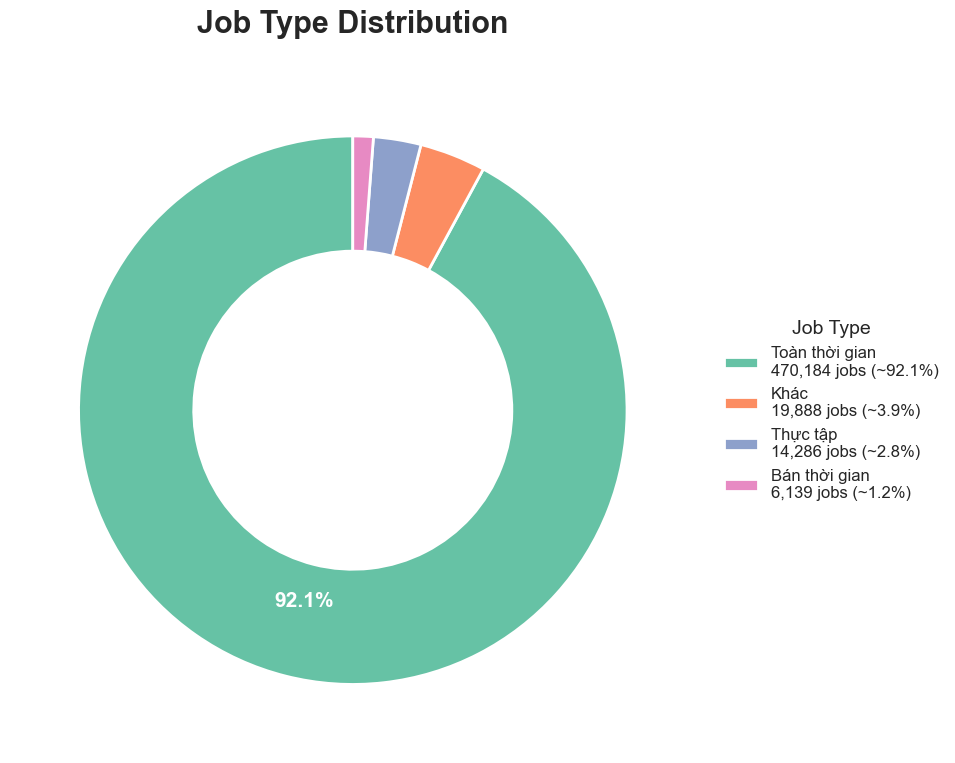

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# =========================
# SEABORN MODERN THEME
# =========================
sns.set_theme(
    style="white",
    context="talk",
    font_scale=1.05
)

# modern palette
pie_colors = sns.color_palette("Set2", 4)

# =========================
# PREPROCESS
# =========================
job_type = df['job_type'].fillna('Khác').str.lower()

job_type_grouped = pd.Series(
    job_type.apply(lambda x:
        'Toàn thời gian' if 'toàn thời gian' in x else
        'Thực tập' if 'thực tập' in x else
        'Bán thời gian' if 'bán thời gian' in x else
        'Khác'
    )
)

job_type_counts = job_type_grouped.value_counts()

total = job_type_counts.sum()
percentages = job_type_counts / total * 100

# =========================
# AUTOPCT
# chỉ hiện trực tiếp nếu > 5%
# =========================
def autopct_format(pct):
    return f'{pct:.1f}%' if pct > 5 else ''

# =========================
# FIGURE
# =========================
fig, ax = plt.subplots(figsize=(20, 8))

wedges, texts, autotexts = ax.pie(
    job_type_counts,
    labels=None,
    autopct=autopct_format,
    startangle=90,
    pctdistance=0.72,
    colors=pie_colors,
    shadow=False,
    wedgeprops={
        'width': 0.42,      # donut thickness
        'edgecolor': 'white',
        'linewidth': 2
    },
    textprops={
        'fontsize': 15,
        'fontweight': 'bold',
        'color': 'white'
    }
)

# =========================
# CENTER CIRCLE
# =========================
centre_circle = plt.Circle(
    (0, 0),
    0.45,
    fc='white'
)

fig.gca().add_artist(centre_circle)

# =========================
# LEGEND
# =========================
legend_labels = [
    f"{label}\n{count:,} jobs (~{pct:.1f}%)"
    for label, count, pct in zip(
        job_type_counts.index,
        job_type_counts.values,
        percentages.values
    )
]

ax.legend(
    wedges,
    legend_labels,
    title="Job Type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=12,
    title_fontsize=14
)

# =========================
# TITLE
# =========================
ax.set_title(
    "Job Type Distribution",
    fontsize=22,
    fontweight='bold',
    pad=25
)

plt.tight_layout()
plt.show()

/var/folders/kl/wl9qbcgd7d199zkz7dg9x6sc0000gn/T/ipykernel_11228/3392817467.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


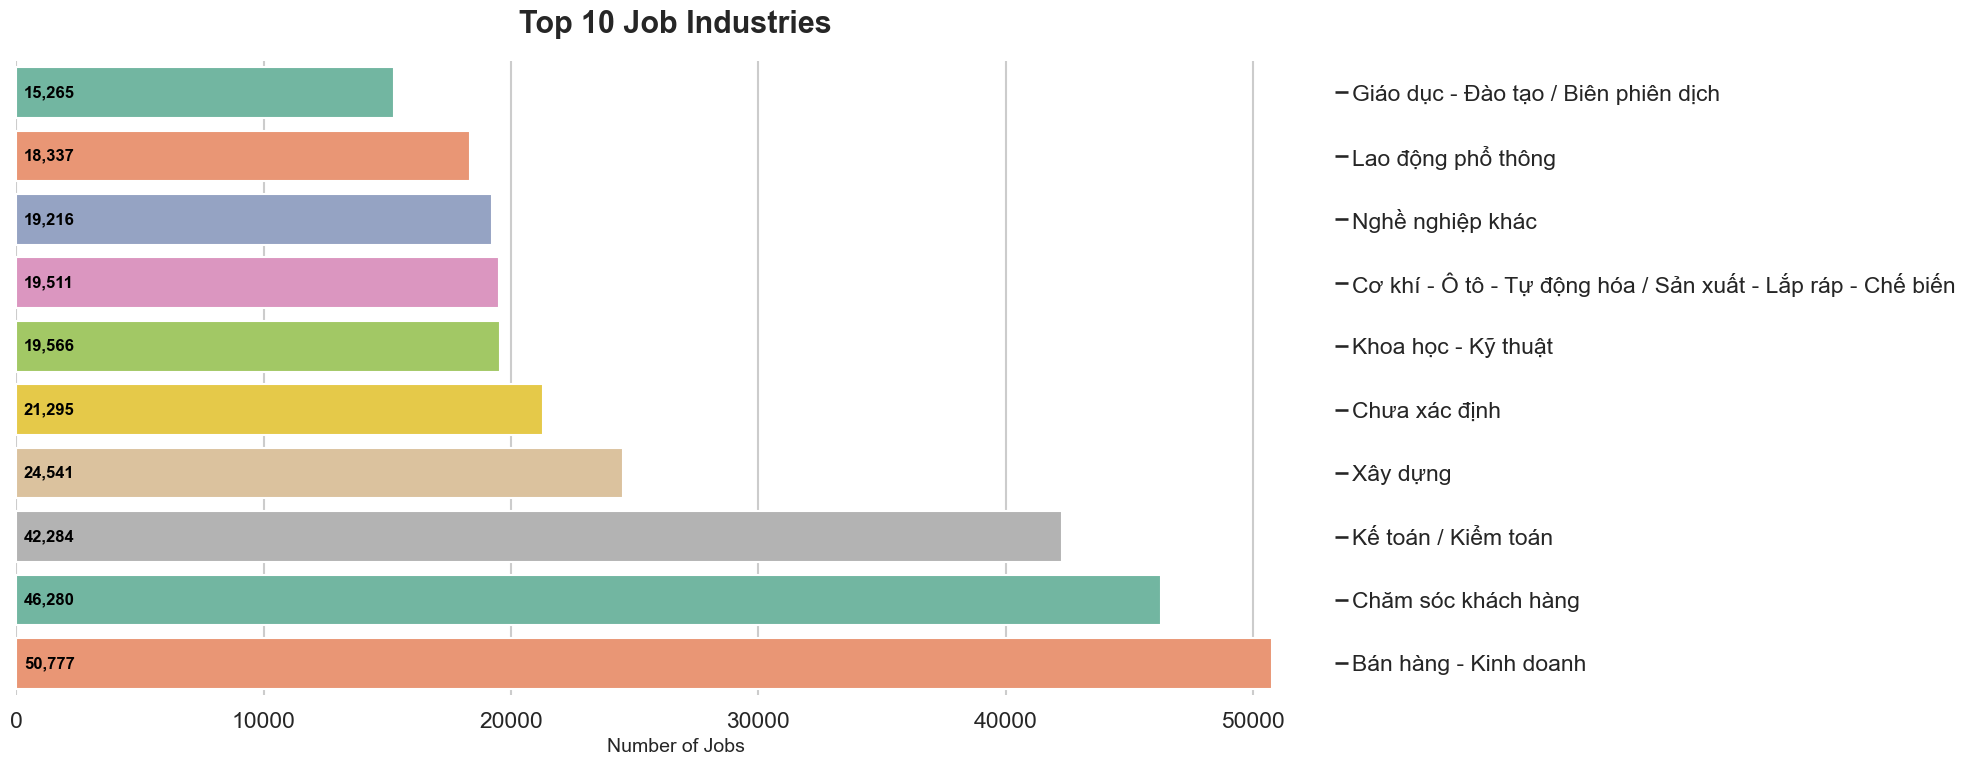

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# STYLE
# =========================
sns.set_theme(
    style="whitegrid",
    context="talk"
)

# =========================
# DATA
# =========================
top_industry = (
    df['job_industry']
    .value_counts()
    .head(10)
    .sort_values()
)

# =========================
# FIGURE
# =========================
fig, ax = plt.subplots(figsize=(20, 8))

sns.barplot(
    x=top_industry.values,
    y=top_industry.index,
    palette="Set2",
    ax=ax
)

# =========================
# VALUE LABELS (LEFT SIDE)
# =========================
for i, value in enumerate(top_industry.values):

    ax.text(
        300,              # cố định gần bên trái
        i,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=12,
        fontweight='bold',
        color='black'
    )

# =========================
# MOVE CATEGORY LABELS RIGHT
# =========================
ax.yaxis.tick_right()

# =========================
# TITLES
# =========================
ax.set_title(
    "Top 10 Job Industries",
    fontsize=22,
    fontweight='bold',
    pad=20
)

ax.set_xlabel(
    "Number of Jobs",
    fontsize=14
)

ax.set_ylabel("")

# =========================
# CLEAN
# =========================
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

/var/folders/kl/wl9qbcgd7d199zkz7dg9x6sc0000gn/T/ipykernel_11228/1890279621.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


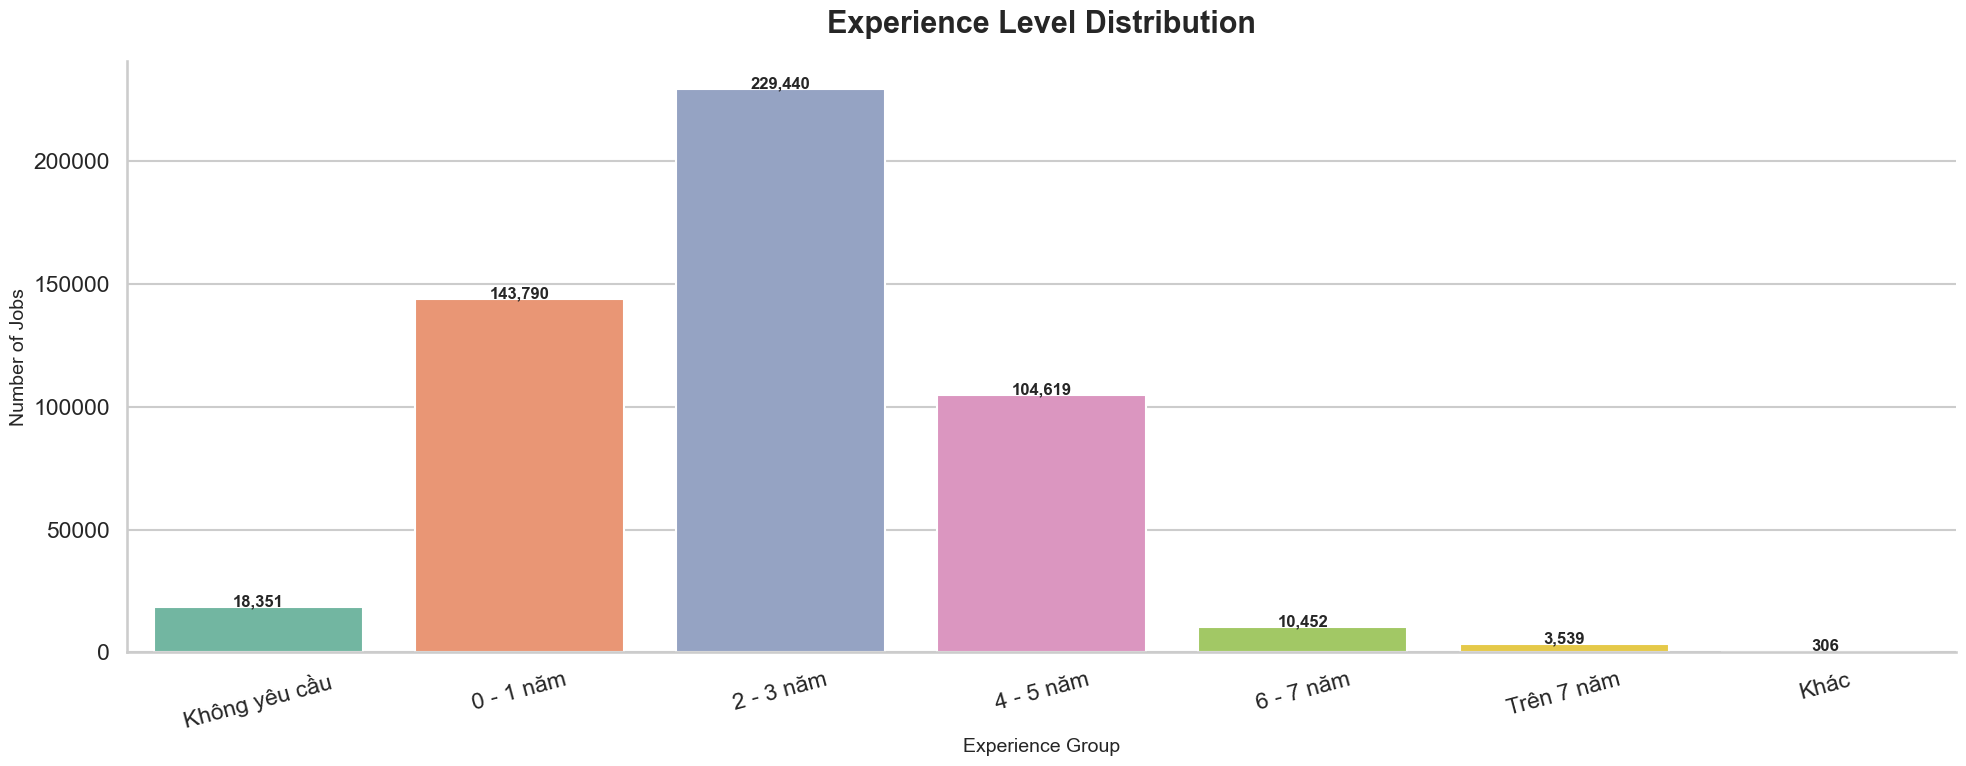

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# MODERN STYLE
# =========================
sns.set_theme(
    style="whitegrid",
    context="talk"
)

# =========================
# CLEAN EXPERIENCE TEXT
# =========================
exp = (
    df['experience_level']
    .fillna('Không yêu cầu')
    .str.lower()
    .str.strip()
)

# =========================
# EXTRACT EXPERIENCE VALUE
# =========================
def extract_exp_bucket(text):

    nums = re.findall(r'\d+', text)

    if 'không' in text:
        return 'Không yêu cầu'

    elif len(nums) == 0:
        return 'Khác'

    # lấy số lớn nhất trong chuỗi
    max_year = max(map(int, nums))

    if max_year <= 1:
        return '0 - 1 năm'

    elif max_year <= 3:
        return '2 - 3 năm'

    elif max_year <= 5:
        return '4 - 5 năm'

    elif max_year <= 7:
        return '6 - 7 năm'

    else:
        return 'Trên 7 năm'

# =========================
# APPLY
# =========================
exp_grouped = exp.apply(extract_exp_bucket)

# =========================
# ORDER
# =========================
exp_order = [
    'Không yêu cầu',
    '0 - 1 năm',
    '2 - 3 năm',
    '4 - 5 năm',
    '6 - 7 năm',
    'Trên 7 năm',
    'Khác'
]

exp_counts = (
    exp_grouped
    .value_counts()
    .reindex(exp_order)
    .dropna()
)

# =========================
# FIGURE
# =========================
fig, ax = plt.subplots(figsize=(20, 8))

sns.barplot(
    x=exp_counts.index,
    y=exp_counts.values,
    palette="Set2",
    ax=ax
)

# =========================
# VALUE LABELS
# =========================
for i, value in enumerate(exp_counts.values):

    ax.text(
        i,
        value + 300,
        f'{value:,}',
        ha='center',
        fontsize=12,
        fontweight='bold'
    )

# =========================
# TITLES
# =========================
ax.set_title(
    "Experience Level Distribution",
    fontsize=22,
    fontweight='bold',
    pad=20
)

ax.set_xlabel(
    "Experience Group",
    fontsize=14
)

ax.set_ylabel(
    "Number of Jobs",
    fontsize=14
)

plt.xticks(rotation=15)

# =========================
# CLEAN STYLE
# =========================
sns.despine()

plt.tight_layout()
plt.show()

In [10]:
# Train/test đã load sẵn ở cell trên (từ clean_data_train.csv + clean_data_test.csv)
# Các cell so sánh distribution train vs test bên dưới dùng trực tiếp 2 biến này
print(f'Train: {train_df.shape}')
print(f'Test : {test_df.shape}')

Train: (453679, 21)
Test : (56818, 21)


In [11]:
Q1 = df['salary_min'].quantile(0.25)
Q3 = df['salary_min'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['salary_min'] < lower_bound) |
    (df['salary_min'] > upper_bound)
]

print(f"Số lượng outlier: {len(outliers):,}")

Số lượng outlier: 25,286


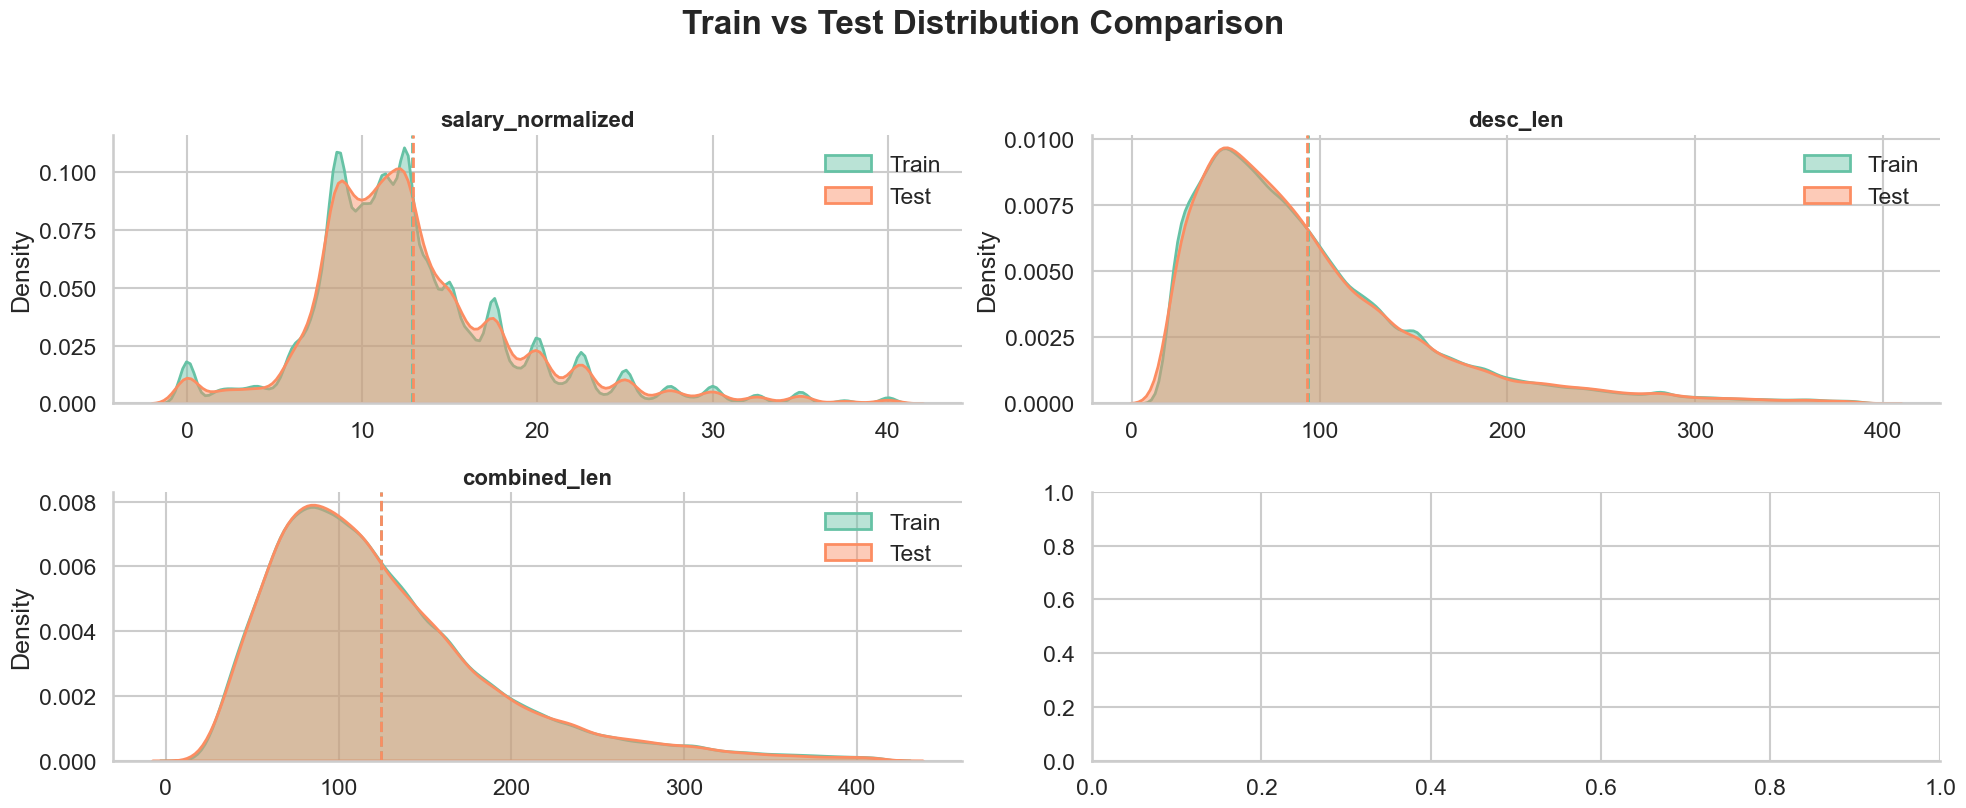

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# =========================
# MODERN STYLE
# =========================
sns.set_theme(
    style="whitegrid",
    context="talk"
)

# =========================
# FEATURES
# =========================
important_num_cols = [
    'salary_normalized',
    
    'desc_len',
    'combined_len'
    
]

# =========================
# COLORS
# =========================
palette = sns.color_palette("Set2", 2)

# =========================
# PLOT
# =========================
fig, axes = plt.subplots(
    2,
    2,
    figsize=(20, 8)
)

axes = axes.flatten()

for ax, col in zip(axes, important_num_cols):

    # remove NA
    train_vals = train_df[col].dropna()
    test_vals = test_df[col].dropna()

    # =========================
    # ZOOM MAIN DISTRIBUTION
    # bỏ tail quá lớn
    # =========================
    upper_limit = np.percentile(
        pd.concat([train_vals, test_vals]),
        99
    )

    train_vals = train_vals[train_vals <= upper_limit]
    test_vals = test_vals[test_vals <= upper_limit]

    # =========================
    # KDE PLOT
    # =========================
    sns.kdeplot(
        train_vals,
        fill=True,
        alpha=0.45,
        linewidth=2,
        label='Train',
        color=palette[0],
        ax=ax
    )

    sns.kdeplot(
        test_vals,
        fill=True,
        alpha=0.45,
        linewidth=2,
        label='Test',
        color=palette[1],
        ax=ax
    )

    # =========================
    # MEAN LINES
    # =========================
    ax.axvline(
        train_vals.mean(),
        linestyle='--',
        linewidth=2,
        color=palette[0]
    )

    ax.axvline(
        test_vals.mean(),
        linestyle='--',
        linewidth=2,
        color=palette[1]
    )

    # =========================
    # TITLES
    # =========================
    ax.set_title(
        f'{col}',
        fontsize=16,
        fontweight='bold'
    )

    ax.set_xlabel("")
    ax.set_ylabel("Density")

    ax.legend(frameon=False)

# =========================
# GLOBAL TITLE
# =========================
fig.suptitle(
    "Train vs Test Distribution Comparison",
    fontsize=24,
    fontweight='bold',
    y=1.02
)

# =========================
# CLEAN STYLE
# =========================
sns.despine()

plt.tight_layout()
plt.show()

/var/folders/kl/wl9qbcgd7d199zkz7dg9x6sc0000gn/T/ipykernel_11228/3927389126.py:115: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/var/folders/kl/wl9qbcgd7d199zkz7dg9x6sc0000gn/T/ipykernel_11228/3927389126.py:115: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/var/folders/kl/wl9qbcgd7d199zkz7dg9x6sc0000gn/T/ipykernel_11228/3927389126.py:115: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


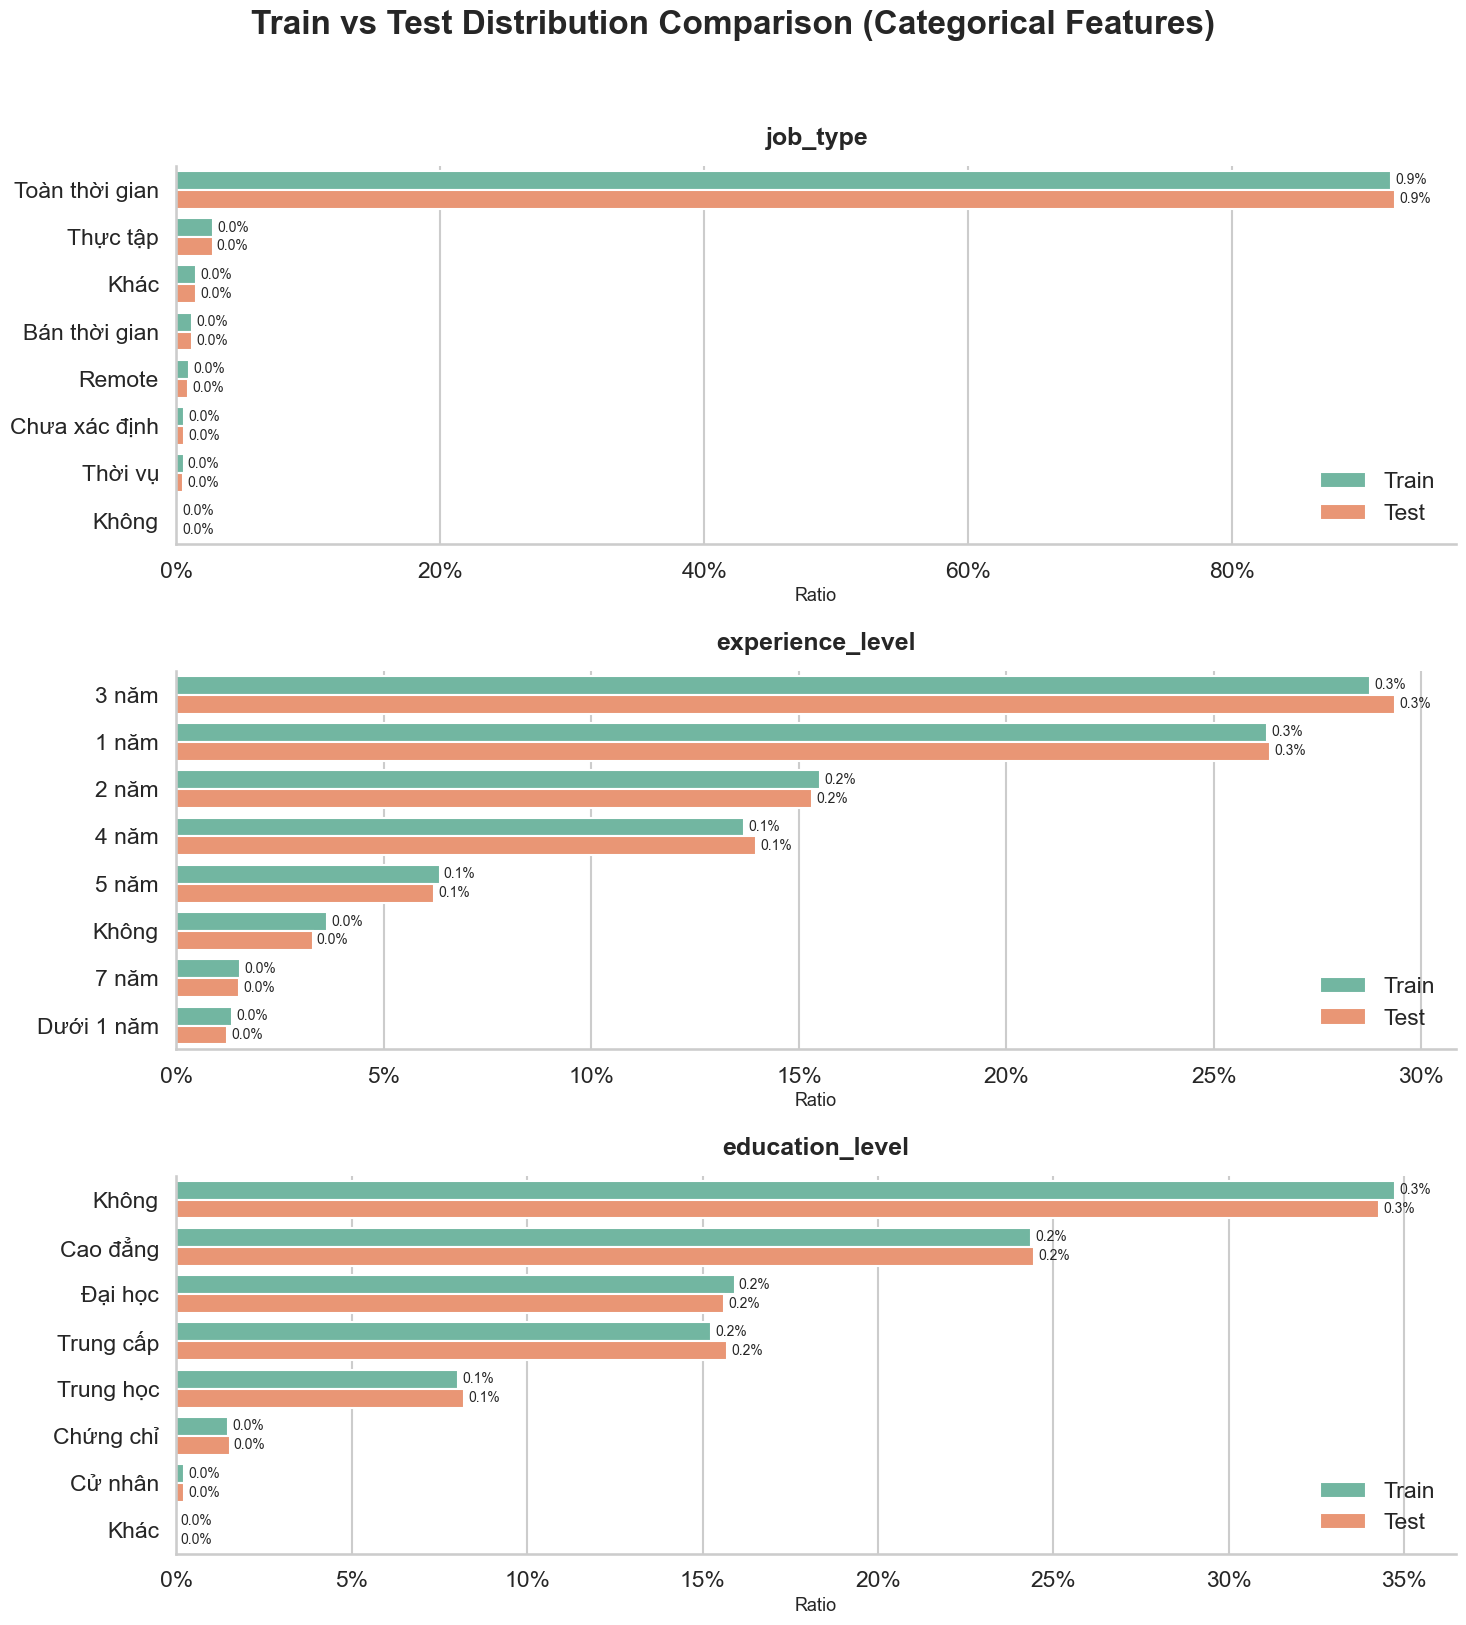

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =========================
# MODERN SEABORN STYLE
# =========================
sns.set_theme(
    style="whitegrid",
    context="talk"
)

# =========================
# COLOR PALETTE
# =========================
palette = sns.color_palette("Set2", 2)

# =========================
# IMPORTANT CATEGORICAL FEATURES
# =========================
important_cat_cols = [
    'job_type',
    'experience_level',
    'education_level'
]

# =========================
# FIGURE
# =========================
fig, axes = plt.subplots(
    len(important_cat_cols),
    1,
    figsize=(15, 16)
)

# nếu chỉ có 1 feature thì tránh lỗi iterable
if len(important_cat_cols) == 1:
    axes = [axes]

# =========================
# LOOP THROUGH FEATURES
# =========================
for ax, col in zip(axes, important_cat_cols):

    # -------------------------
    # Distribution ratio
    # -------------------------
    train_dist = train_df[col].fillna('Unknown').value_counts(normalize=True)

    test_dist = test_df[col].fillna('Unknown').value_counts(normalize=True)

    # -------------------------
    # Combine train/test
    # -------------------------
    compare_df = pd.concat(
        [train_dist, test_dist],
        axis=1
    )

    compare_df.columns = ['Train', 'Test']

    compare_df = compare_df.fillna(0)

    # -------------------------
    # Keep only top categories
    # -------------------------
    compare_df['avg_ratio'] = compare_df.mean(axis=1)

    compare_df = (
        compare_df
        .sort_values('avg_ratio', ascending=False)
        .head(8)
        .drop(columns='avg_ratio')
    )

    # -------------------------
    # Reshape for seaborn
    # -------------------------
    plot_df = (
        compare_df
        .reset_index(names='Category')
        .melt(
            id_vars='Category',
            var_name='Dataset',
            value_name='Ratio'
        )
    )

    # -------------------------
    # Horizontal grouped barplot
    # -------------------------
    sns.barplot(
        data=plot_df,
        x='Ratio',
        y='Category',
        hue='Dataset',
        palette=palette,
        ax=ax
    )

    # -------------------------
    # Percentage labels
    # -------------------------
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.1f%%',
            padding=3,
            fontsize=10
        )

    # chuyển ratio -> %
    current_ticks = ax.get_xticks()

    ax.set_xticklabels(
        [f'{x*100:.0f}%' for x in current_ticks]
    )

    # -------------------------
    # Titles
    # -------------------------
    ax.set_title(
        f'{col}',
        fontsize=18,
        fontweight='bold',
        pad=15
    )

    ax.set_xlabel(
        'Ratio',
        fontsize=13
    )

    ax.set_ylabel("")

    # -------------------------
    # Clean legend
    # -------------------------
    ax.legend(
        title='',
        frameon=False
    )

# =========================
# GLOBAL TITLE
# =========================
fig.suptitle(
    "Train vs Test Distribution Comparison (Categorical Features)",
    fontsize=24,
    fontweight='bold',
    y=1.02
)

# =========================
# CLEAN STYLE
# =========================
sns.despine()

plt.tight_layout()
plt.show()